# Objectif 

Illustration du dataset portion5_event_ais 

Date de création : 16/11/2026

In [48]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from datetime import datetime

In [49]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *

# Chargement des données 

## Données de la portion pour la librairie 
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [50]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath, auto_complex=True)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2323, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2671, mmsi: 526,
│   │                                    ais_datetime: 301, src_datetime: 937)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 21kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:0...
│   │         * src_datetime            (src_datetime) datetime64[ns] 7kB 2026-02-25T11:0...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 21kB ...
│   │           atl_lat                 (atl_datetime) float64 21kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 7kB ...
│   │           tir_vessel_lon          (src_datetime) float64 7kB ...
│   │           tir_vessel_lat          (src_datetime) float64 7kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 52kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 52kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 52kB ...
│   │       Attributes:
│   │           description:              Posi

## Données de la portion event
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [51]:
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event = xr.open_datatree(fpath, auto_complex=True)
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 35)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 280B ...
│   Attributes:
│       box_lon_min:       5.921525852249999
│       box_lon_max:       5.962816177675
│       box_lat_min:       42.986809747449996
│       box_lat_max:       43.060361284900004
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/event_0
│   │       Dimensions:         (datetime: 204)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-27T16:13:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 2kB ...
│   │           lat             (datetime) float64 2kB ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 0
│   │           MMSI:                     6
│   ├── Group: /position/event_1
│   │       Dimensions:         (datetime: 148)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T16:10:40 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 1kB ...
│   │           lat             (datetime) float64 1kB ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 1
│   │           MMSI:                     7
│   ├── Group: /position/event_2
│   │       Dimensions:         (datetime: 99)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 792B 2026-02-28T05:58:00 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 792B ...
│   │           lat             (datetime) float64 792B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 2
│   │           MMSI:                     12
│   ├── Group: /position/event_3
│   │       Dimensions:         (datetime: 21)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 168B 2026-02-27T11:35:50 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 168B ...
│   │           lat             (datetime) float64 168B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 3
│   │           MMSI:                     16
│   ├── Group: /position/event_4
│   │       Dimensions:         (datetime: 24)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 192B 2026-02-28T08:57:00 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 192B ...
│   │           lat             (datetime) float64 192B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           sto

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [52]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
print(ds_pos)

<xarray.Dataset> Size: 525MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 526,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 254MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_date

# Illustration du dataset 

## Position des trajectoires 

In [58]:
root_img = os.path.join(
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR,
    f"portion{portion_id}",
    "results_event_ais",
)
root_img_selection = os.path.join(
    root_img,
    "ais_selection"
    )
root_img_spectro = os.path.join(root_img_selection, "spectro")
root_img_signal = os.path.join(root_img_selection, "signal")
root_img_position = os.path.join(root_img_selection, "position")

['event_0', 'event_1', 'event_2', 'event_3', 'event_4']


OSError: [Errno 22] Invalid argument: 'C:\\Users\\baptiste.menetrier\\Desktop\\devPy\\phd\\real_data_analysis\\acouplane\\img\\portion5\\results_event_ais\\ais_selection\\position\\event_ais_position_batch0.png'

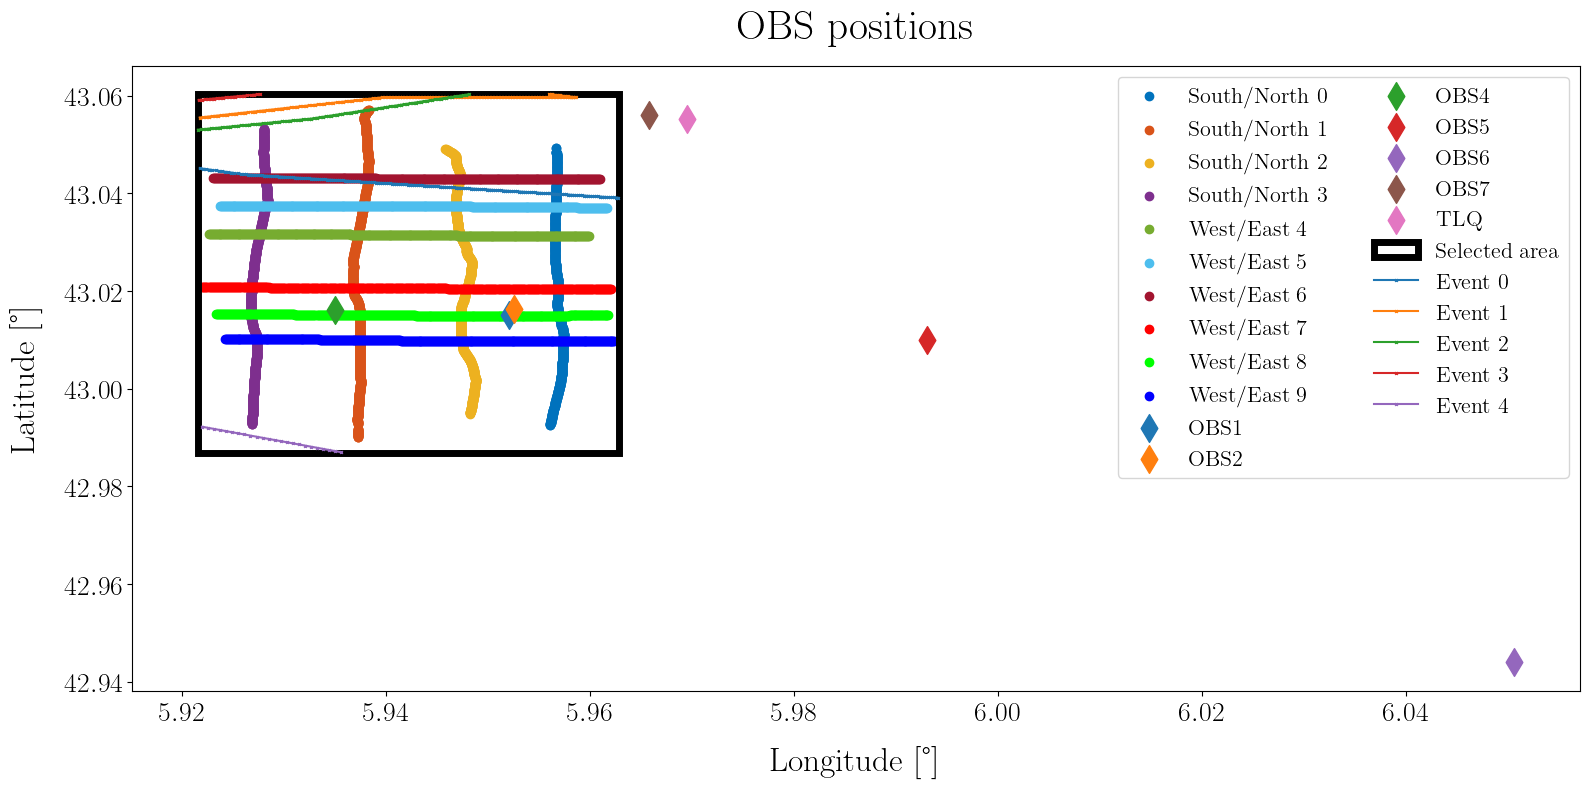

In [54]:
# Plot
batch_size = 5
batch_start = 0
batch_id = 0
while batch_start <= portion_event.event_id.max():

    # portion_event_batch = portion_event.isel(event_id=slice(max(0, last_event_i-batch_size), last_event_i))
    # last_event_i += batch_size
    # print(portion_event_batch)

    event_in_batch = [f"event_{i}" for i in range(batch_start, batch_start+batch_size)]
    batch_start += batch_size
    print(event_in_batch)

    fig, ax = plot_portion_tir_pos(portion_tree=portion)
    ax.add_patch(
        Rectangle(
            (portion_event.box_lon_min, portion_event.box_lat_min),
            portion_event.box_lon_max - portion_event.box_lon_min,
            portion_event.box_lat_max - portion_event.box_lat_min,
            fc="none",
            ec="k",
            lw=5,
            label="Selected area",
        )
    )

    for name, node in portion_event.position.children.items():

        if name not in event_in_batch:
            continue 

        ds_position_section = node.to_dataset()
        plt.plot(
            ds_position_section.lon,
            ds_position_section.lat,
            "-x",
            markersize=2,
            label=f"Event {ds_position_section.event_id}",
        )

    ax.legend()
    legend = ax.get_legend()

    if legend is not None:
        handles = legend.legend_handles
        labels = [text.get_text() for text in legend.get_texts()]

        legend.remove()

        ax.legend(
            handles,
            labels,
            loc="upper right",
            fontsize=16,
            ncols=2,
        )

    fpath = os.path.join(root_img_position, f"event_ais_position_batch{batch_id}.png")
    fig.savefig(fpath)
    plt.close(fig)

    batch_id += 1

## Couverture temporelle 

In [ ]:
event_days = np.concat([
    pd.DatetimeIndex(node.datetime).day
    for name, node in portion_event.position.children.items()
])
event_days, unique_idx = np.unique(event_days, return_index=True)
event_days 

event_months = np.concat(
    [
        pd.DatetimeIndex(node.datetime).month
        for name, node in portion_event.position.children.items()
    ]
)
event_months = event_months[unique_idx]
event_months
event_years = np.concat(
    [
        pd.DatetimeIndex(node.datetime).year
        for name, node in portion_event.position.children.items()
    ]
)
event_years = event_years[unique_idx]

dt_bounds = np.asarray(
    [
        np.datetime64(
            datetime(year=event_years[i], month=event_months[i], day=event_days[i])
        )
        for i in range(event_days.size)
    ]
)
dt_bounds = np.sort(dt_bounds)
dt_bounds

array(['2026-02-24T00:00:00.000000', '2026-02-25T00:00:00.000000',
       '2026-02-27T00:00:00.000000', '2026-02-28T00:00:00.000000',
       '2026-03-01T00:00:00.000000'], dtype='datetime64[us]')

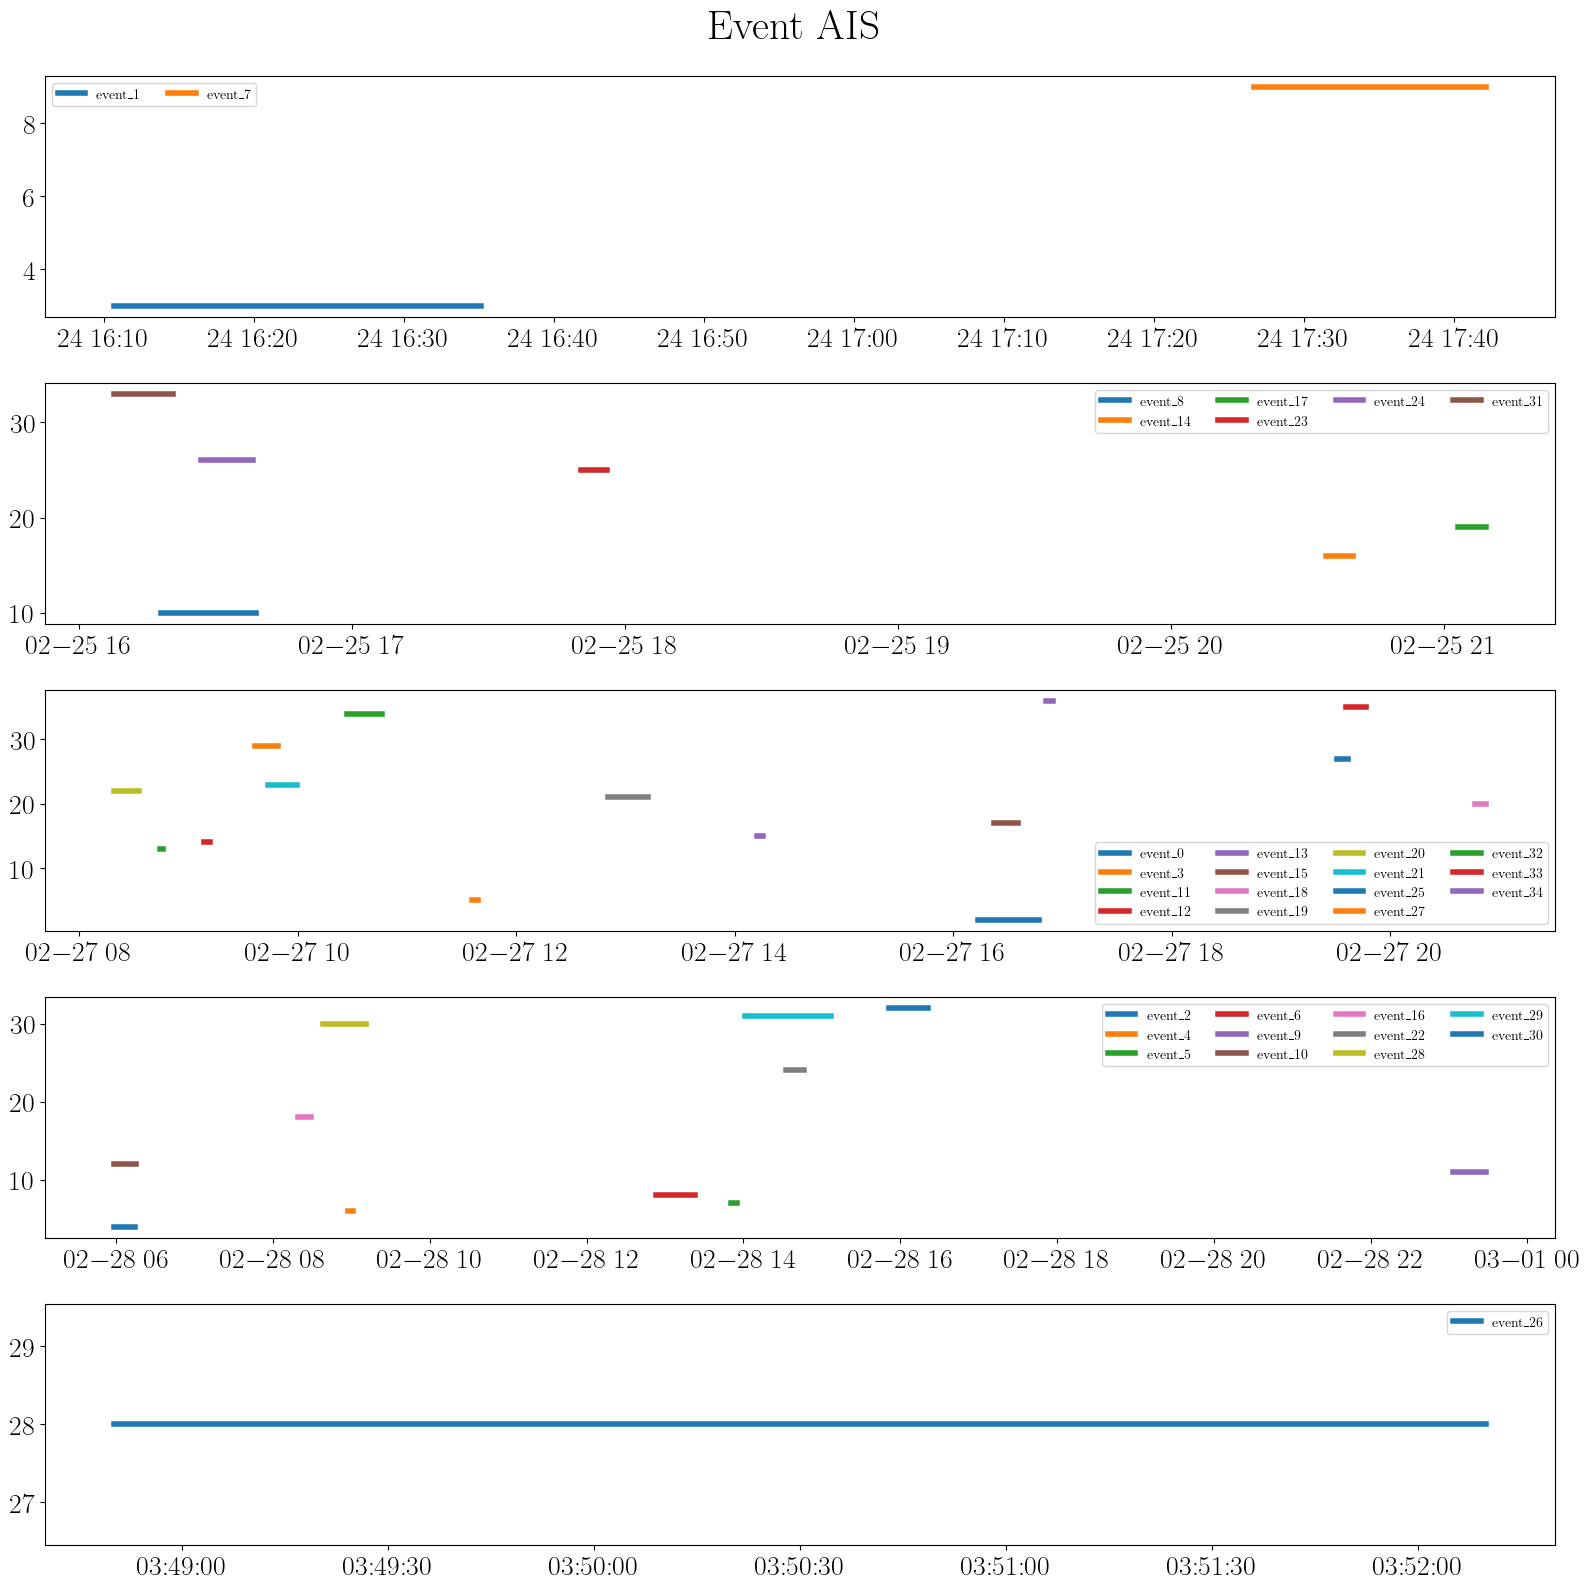

In [56]:
fig, axs = plt.subplots(dt_bounds.size, 1, figsize=(16, 16), sharex=False)

for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    # Choose ax
    dt = ds_position_event.datetime
    if dt.min() <= dt_bounds[1]:
        ax = axs[0]
    elif dt.min() >= dt_bounds[1] and  dt.max() <= dt_bounds[2]:
        ax = axs[1]
    elif dt.min() >= dt_bounds[2] and  dt.max() <= dt_bounds[3]:
        ax = axs[2]
    elif dt.min() >= dt_bounds[3] and  dt.max() <= dt_bounds[4]:
        ax = axs[3]
    elif dt.min() >= dt_bounds[4]:
        ax = axs[4]

    ax.plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id + 1 ,
        linewidth=4,
        label=name
    )

    # ax.legend(fontsize=10)

fig.suptitle("Event AIS")
for ax in axs.flatten():
    ax.legend(fontsize=10, ncols=4)

fpath = os.path.join(root_img_selection, "event_ais_temporal_coverage.png")
fig.savefig(fpath)

## Visualisation des signaux 

ConversionError: Failed to convert value(s) to axis units: array(['2026-02-27T10:26:50.000000000', '2026-02-27T10:26:50.000500000',
       '2026-02-27T10:26:50.001000000', ...,
       '2026-02-27T10:46:29.999000000', '2026-02-27T10:46:29.999500000',
       '2026-02-27T10:46:30.000000000'],
      shape=(2360001,), dtype='datetime64[ns]')

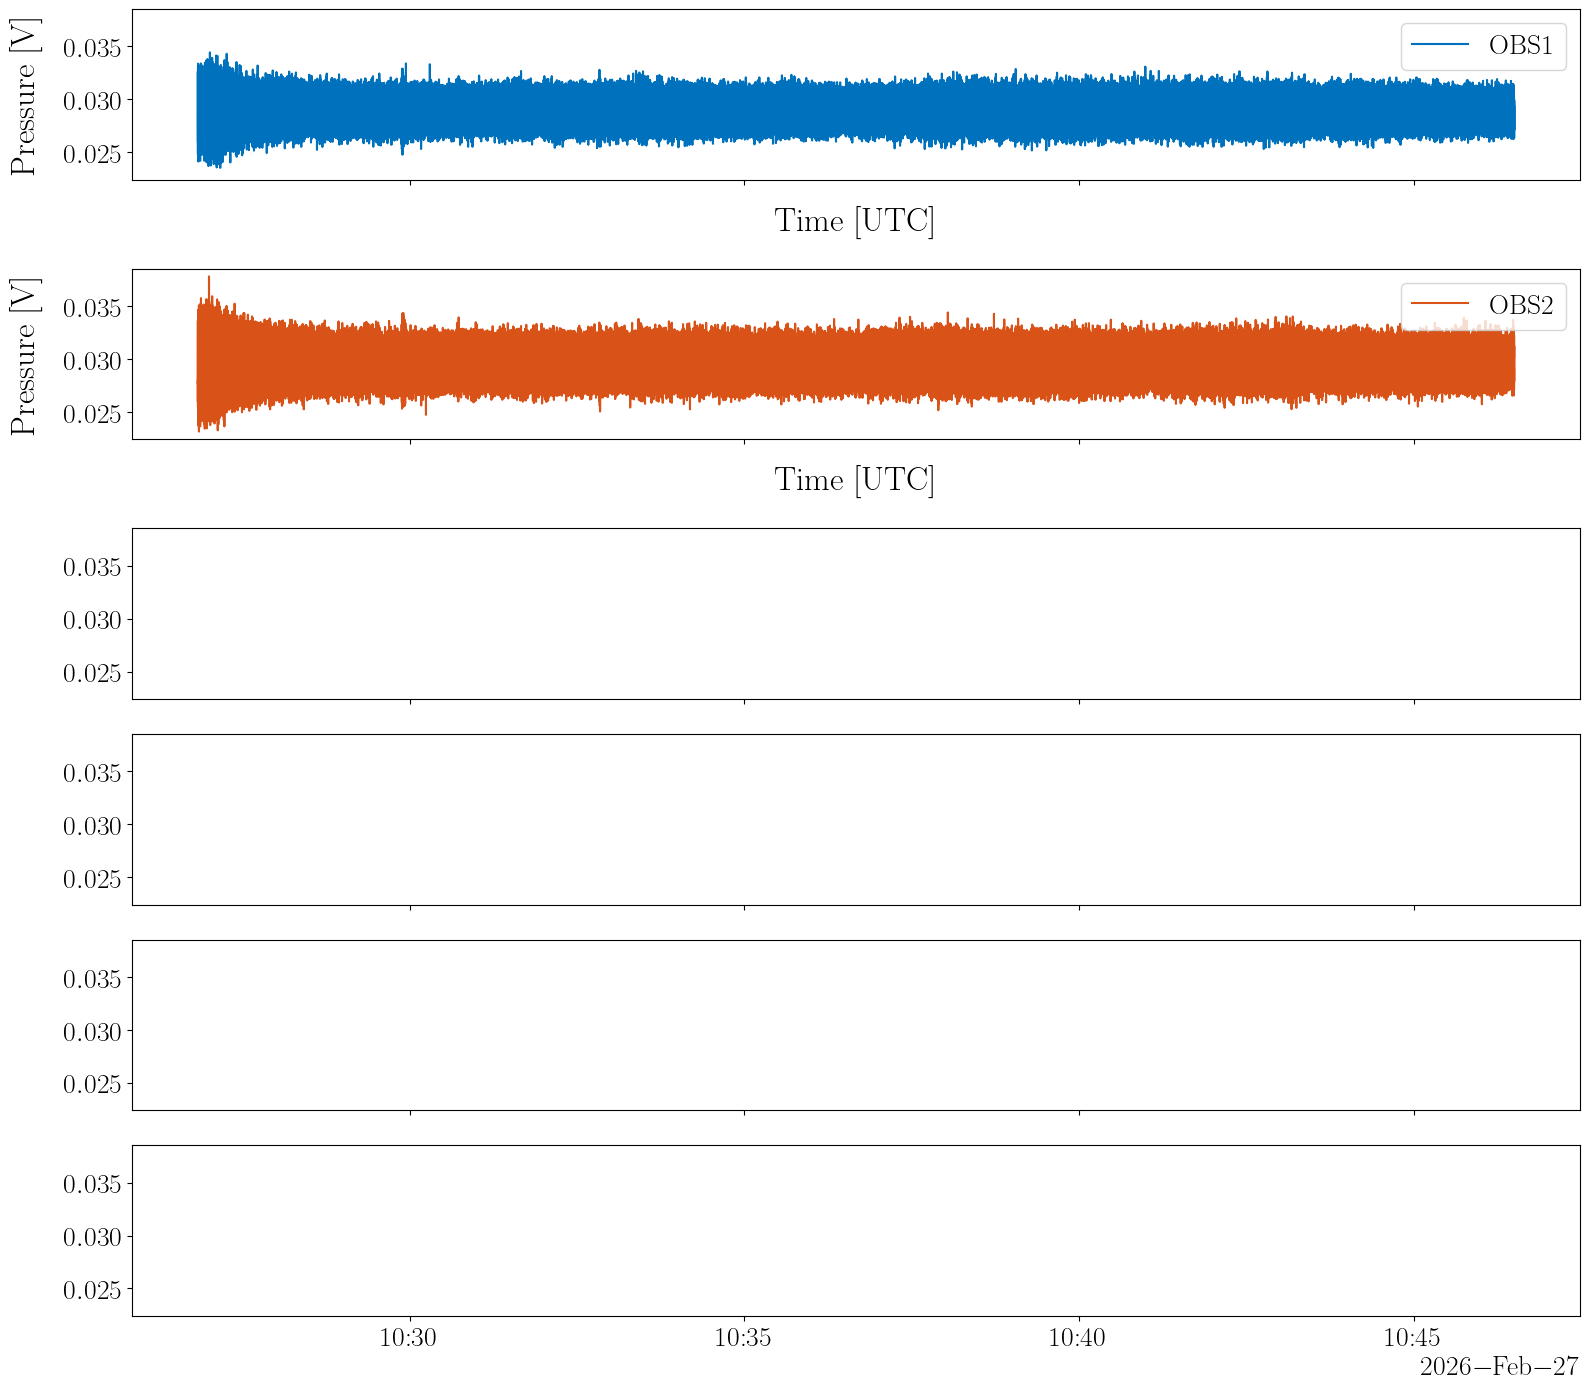

In [59]:
# Plot
single_fig = False
for name, node in portion_event.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"Event {ds_pressure_section.event_id}")

    fpath = os.path.join(root_img_signal, f"signal_ais_{name}")
    fig.savefig(fpath)
    plt.close(fig)

## Spectrogrammes

In [55]:
# Plot
for name, node in portion_event.pressure.children.items():
    print(name)
    ds_pressure_section = node.to_dataset()
    try:
        fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
    except:
        print(f"Data with different length event : {name}")
        continue
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    fpath = os.path.join(root_img_spectro, f"spectro_ais_{name}")
    fig.savefig(fpath)
    plt.close(fig)
    # plt.show()

event_0
event_1
Data with different length event : event_1
event_2
event_3
event_4
event_5


C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_29108\2352764177.py:12: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 30.
  fig.savefig(fpath)


event_6
event_7
event_8
event_9
event_10
event_11
event_12
event_13
event_14
event_15
event_16
event_17
event_18
event_19
event_20
event_21
event_22
event_23
event_24
event_25
event_26
event_27
event_28
event_29
event_30
event_31
event_32
event_33
event_34


In [4]:
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais_mfp.nc"
portion_event_mfp = xr.open_datatree(fpath, auto_complex=True)
portion_event_mfp

<xarray.DataTree>
Group: /
│   Attributes:
│       description:         MFP between a library and events
│       reference_receiver:  obs1
└── Group: /mfp_intersection
    ├── Group: /mfp_intersection/sn0
    │   ├── Group: /mfp_intersection/sn0/event_0
    │   │       Dimensions:                 (rcv_id: 7, library_datetime: 787,
    │   │                                    event_datetime: 809, rcv_id_feature: 5)
    │   │       Coordinates:
    │   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
    │   │         * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
    │   │         * event_datetime          (event_datetime) datetime64[ns] 6kB 2026-02-27T16...
    │   │         * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
    │   │       Data variables: (12/14)
    │   │           rcv_lon                 (rcv_id) float64 56B ...
    │   │           rcv_lat                 (rcv_id) float64 56B ...
    │   │           rcv_immersion           (rcv_id) int16 14B ...
    │   │           library_lon             (library_datetime) float64 6kB ...
    │   │           library_lat             (library_datetime) float64 6kB ...
    │   │           event_lon               (event_datetime) float64 6kB ...
    │   │           ...                      ...
    │   │           d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 25MB ...
    │   │           d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 25MB ...
    │   │           d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 25MB ...
    │   │           d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 25MB ...
    │   │           d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 25MB ...
    │   │           d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 25MB ...
    │   │       Attributes:
    │   │           description:               MFP result for a library section and an event
    │   │           campagne:                  ACOUPLANE
    │   │           section1:                  sn0
    │   │           section2:                  event_0
    │   │           library_acquisition_mode:  active
    │   │           event_acquisition_mode:    passive
    │   │           reference_receiver:        obs1
    │   │           obs_position:              OBS position corrected using LMS inversion.
    │   │           obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...
    │   ├── Group: /mfp_intersection/sn0/event_1
    │   │       Dimensions:                 (rcv_id: 7, library_datetime: 787,
    │   │                                    event_datetime: 121, rcv_id_feature: 5)
    │   │       Coordinates:
    │   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
    │   │         * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
    │   │         * event_datetime          (event_datetime) datetime64[ns] 968B 2026-02-24T1...
    │   │         * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
    │   │       Data variables: (12/14)
    │   │           rcv_lon                 (rcv_id) float64 56B ...
    │   │           rcv_lat                 (rcv_id) float64 56B ...
    │   │           rcv_immersion           (rcv_id) int16 14B ...
    │   │           library_lon             (library_datetime) float64 6kB ...
    │   │           library_lat             (library_datetime) float64 6kB ...
    │   │           event_lon               (event_datetime) float64 968B ...
    │   │           ...                      ...
    │   │           d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 4MB ...
    │   │           d_theta_gamma           (rcv_id_feature, library_datet

In [6]:
portion_event_mfp.mfp_intersection.sn1

<xarray.DataTree 'sn1'>
Group: /mfp_intersection/sn1
├── Group: /mfp_intersection/sn1/event_0
│       Dimensions:                 (rcv_id: 7, library_datetime: 937,
│                                    event_datetime: 809, rcv_id_feature: 5)
│       Coordinates:
│         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│         * library_datetime        (library_datetime) datetime64[ns] 7kB 2026-02-25T...
│         * event_datetime          (event_datetime) datetime64[ns] 6kB 2026-02-27T16...
│         * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
│       Data variables: (12/14)
│           rcv_lon                 (rcv_id) float64 56B ...
│           rcv_lat                 (rcv_id) float64 56B ...
│           rcv_immersion           (rcv_id) int16 14B ...
│           library_lon             (library_datetime) float64 7kB ...
│           library_lat             (library_datetime) float64 7kB ...
│           event_lon               (event_datetime) float64 6kB ...
│           ...                      ...
│           d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 30MB ...
│           d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 30MB ...
│           d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 30MB ...
│           d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 30MB ...
│           d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 30MB ...
│           d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 30MB ...
│       Attributes:
│           description:               MFP result for a library section and an event
│           campagne:                  ACOUPLANE
│           section1:                  sn1
│           section2:                  event_0
│           library_acquisition_mode:  active
│           event_acquisition_mode:    passive
│           reference_receiver:        obs1
│           obs_position:              OBS position corrected using LMS inversion.
│           obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...
├── Group: /mfp_intersection/sn1/event_1
│       Dimensions:                 (rcv_id: 7, library_datetime: 937,
│                                    event_datetime: 121, rcv_id_feature: 5)
│       Coordinates:
│         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│         * library_datetime        (library_datetime) datetime64[ns] 7kB 2026-02-25T...
│         * event_datetime          (event_datetime) datetime64[ns] 968B 2026-02-24T1...
│         * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
│       Data variables: (12/14)
│           rcv_lon                 (rcv_id) float64 56B ...
│           rcv_lat                 (rcv_id) float64 56B ...
│           rcv_immersion           (rcv_id) int16 14B ...
│           library_lon             (library_datetime) float64 7kB ...
│           library_lat             (library_datetime) float64 7kB ...
│           event_lon               (event_datetime) float64 968B ...
│           ...                      ...
│           d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 5MB ...
│           d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 5MB ...
│           d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 5MB ...
│           d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 5MB ...
│           d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 5MB ...
│           d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 5MB ...
│       Attributes:
│           description:               MFP result for a library section and an even